## Evaluation

### Load dataset and model

In [2]:
import argparse
import os.path

import torch
import numpy as np
from torch import nn,optim
from videovae import VAEs
from torch import nn
from torch.utils.data import DataLoader  #Gives easier data management by creating mini batches etc.
from tqdm import tqdm
import matplotlib.pyplot as plt
import random

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VAEs.add_model_specific_args(parser)
# parser.add_argument('--data_path', type=str, default='./datasets/livingroom/')
parser.add_argument('--data_path', type=str, default='./datasets/ATR_1F_3F_2024-12-25')

parser.add_argument('--sequence_length', type=int, default=16)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=30)
args = parser.parse_args(args=[])
squence_length = 16
half_seq_len = int(squence_length/2)

from datasets.video_dataset import VideoDataset
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)



############# Pretrained VAEAC #############
from videovae.pretrained_VAEAC import GaussianLoss, MobileNetDecoder, MobileNetEncoder
reonstruction_log_prob = GaussianLoss()
mobilenet_enc_proposal = MobileNetEncoder(96)
mobilenet_enc_prior = MobileNetEncoder(96)

# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    
    nn.Linear(1024, 2048),
)

generative_network = MobileNetDecoder(96)
from videovae.pretrained_VAEAC import VAEAC
MobileNet_pretrain = VAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
                 MLP_network_proposal, MLP_network_prior, MLP_network_vid, generative_network,
).to(DEVICE)



############# mmVAEAC #############
reonstruction_log_prob = GaussianLoss()
mobilenet_enc_proposal = MobileNet_pretrain.mobilenet_enc_proposal
mobilenet_enc_prior = MobileNet_pretrain.mobilenet_enc_prior

# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

input_mot_channel = squence_length*4
mot_proposal_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

mot_prior_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    nn.Linear(1024, 2048),

)

mot_generative_network = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 32),
    # nn.Sigmoid()
)

mobilenet_generative_network = MobileNet_pretrain.generative_network
from videovae.mmVAEAC import mmVAEAC

# load the mmVAEAC pretrained model
model = mmVAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
    mot_proposal_network, mot_prior_network, MLP_network_proposal, MLP_network_prior, MLP_network_vid, mot_generative_network, mobilenet_generative_network
).to(DEVICE)

# modelData = './checkpoints/pretrained_mmVAEAC/atr_data_epoch_30.pth.tar'  
modelData = './checkpoints/pretrained_mmVAEAC/20250310_atr_data_no_pre_epoch_100.pth.tar'  

# 加载模型和权重
checkpoint = torch.load(modelData)
model.load_state_dict(checkpoint['model_state_dict'])


Human = True

cuda
metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/train/metadata_16.pkl
metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/test/metadata_16.pkl


In [2]:
from eval.utils import is_human

# 保留 is_human 为 True 的样本
def get_human_samples(dataset, num_samples, label):
    human_index = []
    while len(human_index) < num_samples:
        random_indices = random.sample(range(len(dataset)), num_samples - len(human_index))
        for idx in random_indices:
            sample,_,_ = dataset[idx]
            batch, mot = dict.values(sample)
            if is_human(batch, label):
                human_index.append(idx)
        # print(len(human_index))
    return human_index

valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)
human_index = get_human_samples(valid_dataset, 350, label=0.05)
torch.save(human_index, 'eval/human_index_350.pt')


metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/train/metadata_16.pkl


### Evaluate multiple real data's Manhattan distances and calculate the average

In [ ]:
from videovae.utils import gray2color
from visual_utils import save_video
from eval.utils import manhattan_dist

import random
all_manhattan_distance = []

camera_actions =[]
fig = plt.figure(figsize=(20, 10))
im_list = []
im_all = []
scale = 0.25
count = 0
step = 3
last_motion = 'stop'
idx = 8000
# 1200, 8000, 
linear_gt = []
angle_gt = []

# Load the dataset
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

if Human:
    real_data_random_indices = torch.load('eval/human_index_350 copy.pt')
else:
    real_data_random_indices = random.sample(range(len(valid_dataset)), 350)

for real_idx in real_data_random_indices:
    rec_vid_list = []
    rec_mot_list = []

    # Load the batch and motion
    x,_,_ = valid_dataset[idx]

    batch, motion = dict.values(x)
    motion = motion.permute(1,0).to(DEVICE)
    print(batch.shape)
    rec_vid_list.append(batch)
    rec_mot_list.append(motion.reshape(1,args.sequence_length,2))

    # Pick up n idx from the dataset randomly
    # random_indices = random.sample(range(len(valid_dataset)), 50)
    random_indices = random.sample(real_data_random_indices, 50)

    for idx in random_indices:
        x, _, _ = valid_dataset[idx]
        batch, mot = dict.values(x)
        mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

        rec_vid_list.append(batch)
        rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))
    print(len(rec_vid_list))
    frame_t = 8 
    manhattan_distance = manhattan_dist(args, rec_vid_list, rec_mot_list, frame_t, input_dim=9, pooled=True)
    all_manhattan_distance.append(manhattan_distance)
if Human:
    torch.save(all_manhattan_distance, 'eval/human_all_manhattan_distances.pt')
else:
    torch.save(all_manhattan_distance, 'eval/all_manhattan_distances.pt')


metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/train/metadata_16.pkl
torch.Size([16, 64, 64, 9])
51
Frame 1 Manhattan Distances: {'undetected_obs': tensor(0.4013), 'ceiling': tensor(0.1953), 'wall': tensor(0.1573), 'detected_furniture': tensor(0.0073), 'door': tensor(0.0071), 'Human': tensor(0.0137), 'Floor': tensor(0.2243)}
Frame 2 Manhattan Distances: {'undetected_obs': tensor(0.2006), 'ceiling': tensor(0.1364), 'wall': tensor(0.1654), 'detected_furniture': tensor(0.0120), 'door': tensor(0.0119), 'Human': tensor(0.2051), 'Floor': tensor(0.1501)}
Frame 3 Manhattan Distances: {'undetected_obs': tensor(0.1774), 'ceiling': tensor(0.0772), 'wall': tensor(0.1611), 'detected_furniture': tensor(0.0072), 'door': tensor(0.0077), 'Human': tensor(0.0254), 'Floor': tensor(0.1219)}
Frame 4 Manhattan Distances: {'undetected_obs': tensor(0.1740), 'ceiling': tensor(0.1097), 'wall': tensor(0.2142), 'detected_furniture': tensor(0.0190), 'door': tensor(0.0070), 'Human': tensor(0.0293), 'Floor': ten

<Figure size 2000x1000 with 0 Axes>

In [4]:
if Human:
    all_distances = torch.load('eval/human_all_manhattan_distances.pt')
else:  
    all_distances = torch.load('eval/all_manhattan_distances_350x50.pt')

all_sorted_distances = []
channels = ['undetected_obs', 'ceiling', 'wall', 'detected_furniture', 'door', 'Human', 'Floor']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
if Human:
    torch.save(average_distances, 'eval/average_manhattan_distances_human_data.pt')
else:
    torch.save(average_distances, 'eval/average_manhattan_distances_real_data.pt')

350
Average Manhattan Distances for Each Sample:
Sample 1: {'undetected_obs': tensor(0.1208), 'ceiling': tensor(0.0524), 'wall': tensor(0.0742), 'detected_furniture': tensor(0.0163), 'door': tensor(0.0068), 'Human': tensor(0.0180), 'Floor': tensor(0.0519)}
Sample 2: {'undetected_obs': tensor(0.1580), 'ceiling': tensor(0.0697), 'wall': tensor(0.0970), 'detected_furniture': tensor(0.0218), 'door': tensor(0.0086), 'Human': tensor(0.0241), 'Floor': tensor(0.0710)}
Sample 3: {'undetected_obs': tensor(0.1692), 'ceiling': tensor(0.0751), 'wall': tensor(0.1033), 'detected_furniture': tensor(0.0226), 'door': tensor(0.0090), 'Human': tensor(0.0266), 'Floor': tensor(0.0783)}
Sample 4: {'undetected_obs': tensor(0.1761), 'ceiling': tensor(0.0785), 'wall': tensor(0.1069), 'detected_furniture': tensor(0.0231), 'door': tensor(0.0092), 'Human': tensor(0.0277), 'Floor': tensor(0.0835)}
Sample 5: {'undetected_obs': tensor(0.1819), 'ceiling': tensor(0.0814), 'wall': tensor(0.1096), 'detected_furniture': t

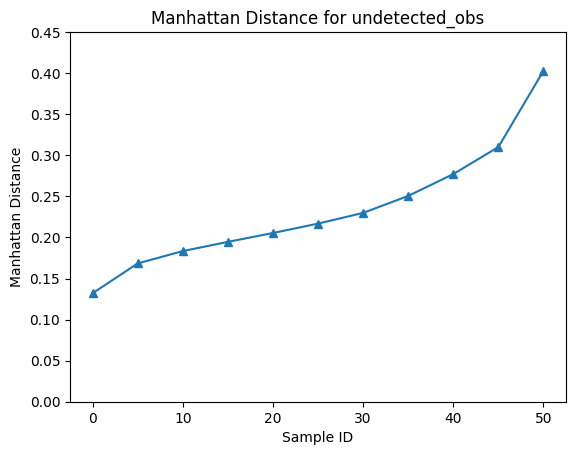

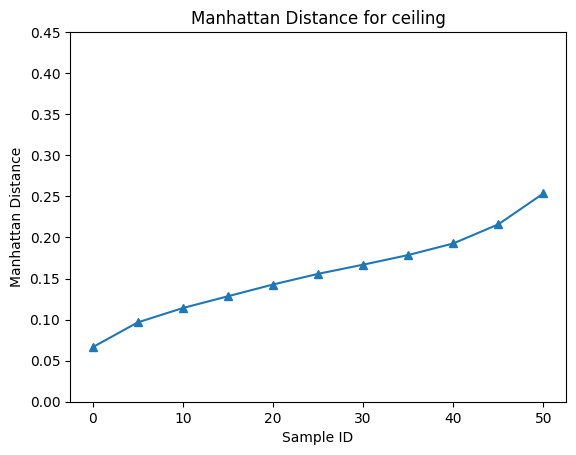

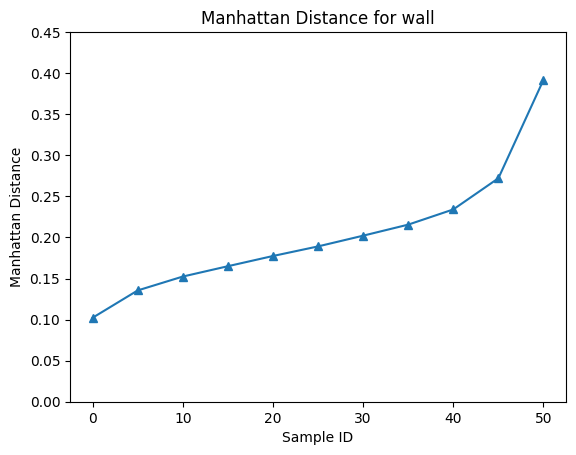

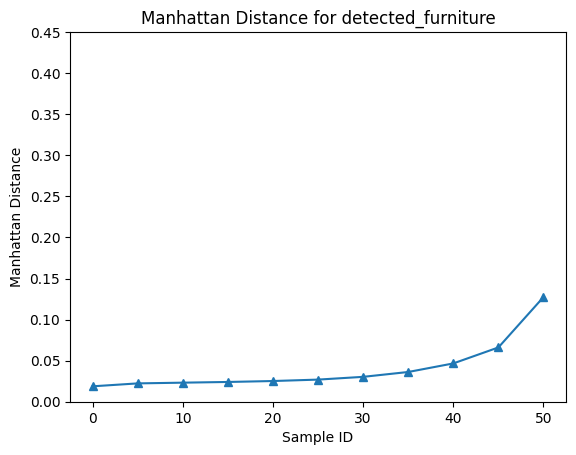

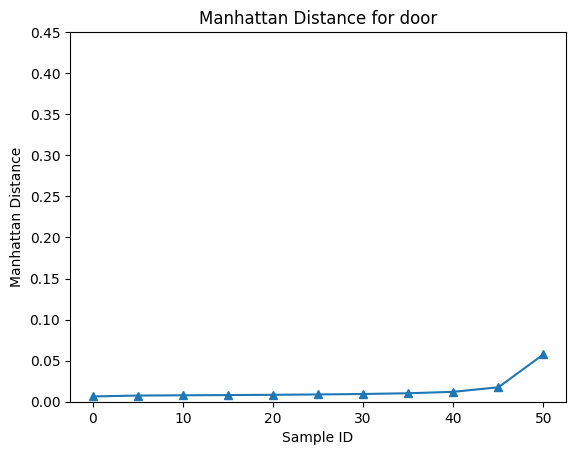

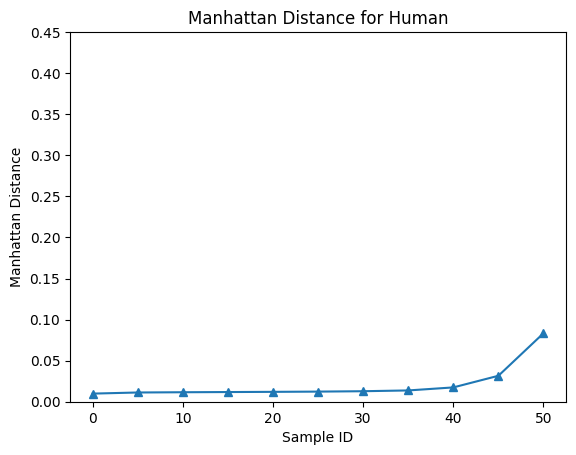

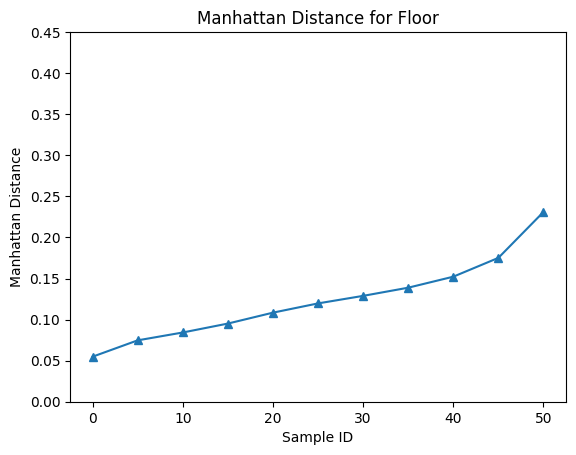

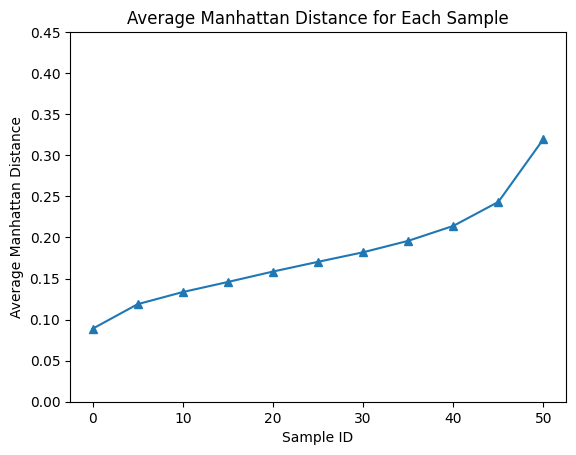

In [7]:
from eval.utils import visual_MD

# 读取 .pt 文件
if Human:
    distances = torch.load('eval/average_manhattan_distances_human_data.pt')
else:
    distances = torch.load('eval/average_manhattan_distances_real_data.pt')
visual_MD(distances)

### Evaluate real data v.s. generated samples

In [10]:
from videovae.mmVAEAC import VideoFixedSequenceGenerator
from videovae.pretrained_VAEAC import sampler
import random   
from eval.utils import rpe

all_manhattan_distance = []
mask_generator = VideoFixedSequenceGenerator()
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

if Human:
    real_data_random_indices = torch.load('eval/human_index_350 copy.pt')
else:
    real_data_random_indices = random.sample(range(len(valid_dataset)), 350)
for real_idx in real_data_random_indices:
    print(real_idx)
    pred_num = 50
    rec_vid_list = []
    rec_mot_list = []

    x, _,_ = valid_dataset[real_idx]
    batch, motion = dict.values(x)
    batch = batch.reshape(1,squence_length,64,64,9).to(DEVICE)
    motion = motion.permute(1,0).to(DEVICE)
    rec_vid_list.append(batch)
    rec_mot_list.append(motion.reshape(1,args.sequence_length,2))
    
    for i in range(pred_num):
        x, _,_ = valid_dataset[real_idx]
        batch, motion = dict.values(x)
        batch = batch.reshape(1,squence_length,64,64,9).to(DEVICE)
        motion = motion.permute(1,0).to(DEVICE)
        
        mot = motion.reshape(1,squence_length,2)

        # without guide
        # mask_batch = mask_generator(batch).to(DEVICE)
        # with guide
        mask_batch = torch.zeros_like(batch).to(DEVICE)

        mask_motion = mask_generator(mot)
        with torch.no_grad():
            # Reconstruct the unobserved features
            rec_params_vid, rec_params_mot = model.generate_samples_params(batch, mot, mask_batch, mask_motion)
            # print(rec_params_vid.shape)
            img_samples = sampler(rec_params_vid)
            mot_samples = rec_params_mot.reshape(1,squence_length,2)

            # Preprocess for visualization (8 observed frames + 8 reconstructed frames)
            model_input = batch.permute(0,4,1,2,3).to(DEVICE)
            mask = mask_batch.permute(0,4,1,2,3)
            model_input[mask.byte()] = 0
            img_samples[1-mask.byte()] = 0
            img_samples += model_input
            video_clip = img_samples.permute(0,2,3,4,1)
            rec_vid_list.append(video_clip)
            rec_mot_list.append(mot_samples)
        # print(video_clip.shape)
        # print(mot_samples.shape)

    rpe_distance = rpe(args, rec_vid_list, rec_mot_list, 8)
    all_manhattan_distance.append(rpe_distance)
    
if Human:
    torch.save(all_manhattan_distance, 'eval/human_action_with_guide_350x50.pt')
else:
    torch.save(all_manhattan_distance, 'eval/action_with_guide_350x50.pt')
  
 


metadata exists in: ./datasets/ATR_1F_3F_2024-12-25/train/metadata_16.pkl
11095
Frame 1 RPE: {'translation': tensor(0.0354, device='cuda:0'), 'rotation': tensor(0.2693, device='cuda:0')}
Frame 2 RPE: {'translation': tensor(0.0291, device='cuda:0'), 'rotation': tensor(0.2247, device='cuda:0')}
Frame 3 RPE: {'translation': tensor(0.0484, device='cuda:0'), 'rotation': tensor(0.2007, device='cuda:0')}
Frame 4 RPE: {'translation': tensor(0.0263, device='cuda:0'), 'rotation': tensor(0.2294, device='cuda:0')}
Frame 5 RPE: {'translation': tensor(0.0545, device='cuda:0'), 'rotation': tensor(0.1948, device='cuda:0')}
Frame 6 RPE: {'translation': tensor(0.0274, device='cuda:0'), 'rotation': tensor(0.2266, device='cuda:0')}
Frame 7 RPE: {'translation': tensor(0.0743, device='cuda:0'), 'rotation': tensor(0.1754, device='cuda:0')}
Frame 8 RPE: {'translation': tensor(0.0280, device='cuda:0'), 'rotation': tensor(0.2596, device='cuda:0')}
Frame 9 RPE: {'translation': tensor(0.0517, device='cuda:0'), 'r

In [11]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval/human_action_with_guide_350x50.pt')

# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['translation', 'rotation']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval/sorted_manhattan_distances_generated.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# sorted_distances = torch.load('eval/sorted_manhattan_distances_generated.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average RPE for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval/average_action_with_guide_350x50.pt')

# Visualize the results
# from eval.utils import visual_rpe

# # 读取 .pt 文件
# distances = torch.load('eval_action/action_average_RPE_generated_with_guide.pt')
# visual_rpe(distances)

350
Average RPE for Each Sample:
Sample 1: {'translation': tensor(0.0291), 'rotation': tensor(0.1438)}
Sample 2: {'translation': tensor(0.0310), 'rotation': tensor(0.1526)}
Sample 3: {'translation': tensor(0.0323), 'rotation': tensor(0.1577)}
Sample 4: {'translation': tensor(0.0335), 'rotation': tensor(0.1612)}
Sample 5: {'translation': tensor(0.0345), 'rotation': tensor(0.1643)}
Sample 6: {'translation': tensor(0.0355), 'rotation': tensor(0.1668)}
Sample 7: {'translation': tensor(0.0366), 'rotation': tensor(0.1691)}
Sample 8: {'translation': tensor(0.0376), 'rotation': tensor(0.1712)}
Sample 9: {'translation': tensor(0.0386), 'rotation': tensor(0.1732)}
Sample 10: {'translation': tensor(0.0396), 'rotation': tensor(0.1751)}
Sample 11: {'translation': tensor(0.0404), 'rotation': tensor(0.1768)}
Sample 12: {'translation': tensor(0.0415), 'rotation': tensor(0.1784)}
Sample 13: {'translation': tensor(0.0425), 'rotation': tensor(0.1800)}
Sample 14: {'translation': tensor(0.0435), 'rotation'

## Combined result

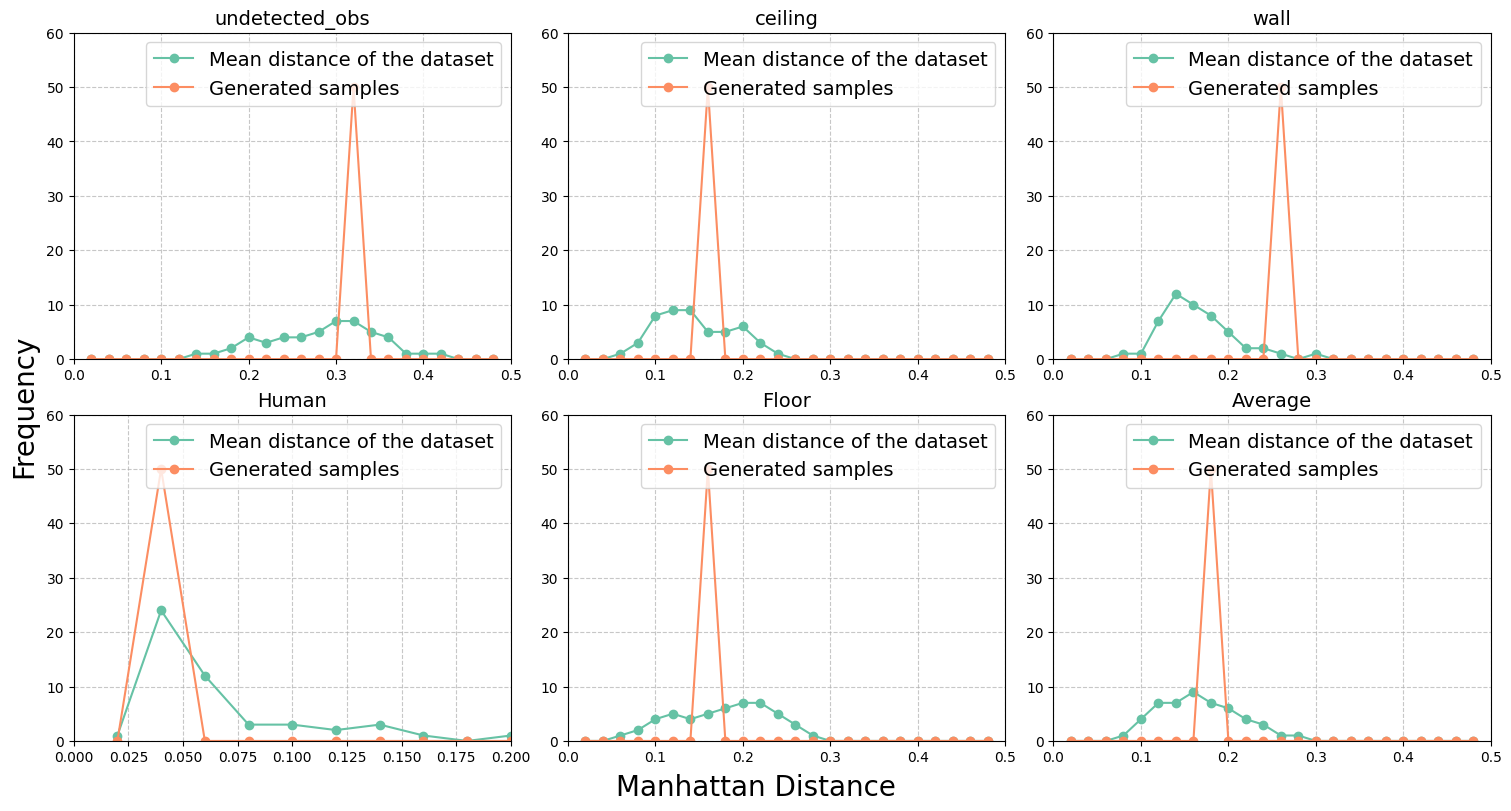

In [8]:
import torch
if Human:
    manhattan_distance_1 = torch.load('eval/average_manhattan_distances_human_data.pt')
    manhattan_distance_2 = torch.load('eval/average_manhattan_distances_human_generated.pt')
else:
    manhattan_distance_1 = torch.load('eval/average_manhattan_distances_real_data.pt')
    manhattan_distance_2 = torch.load('eval/average_manhattan_distances_generated.pt')
# print(manhattan_distance_2)
from eval.utils import visual_MD_combined
visual_MD_combined(manhattan_distance_1, manhattan_distance_2, Freq=True)    

## The action result

In [14]:
import torch

# 假设 RPE_with_guide 是一个包含 50 个 sample 的列表，每个 sample 是一个字典，包含 translation 和 rotation 数据
RPE_with_guide = torch.load('eval/average_action_with_guide_350x50.pt')
RPE_without_guide = torch.load('eval/average_action_no_guide_350x50.pt')

# 初始化列表以存储所有 sample 的 translation 和 rotation 数据
translations_with_guide = []
rotations_with_guide = []

translations_without_guide = []
rotations_without_guide = []

# 遍历每个 sample，并分别提取 translation 和 rotation 数据
for sample, RPE in RPE_with_guide.items():
    translations_with_guide.append(RPE['translation'])
    rotations_with_guide.append(RPE['rotation'])

for sample, RPE in RPE_without_guide.items():
    translations_without_guide.append(RPE['translation'])
    rotations_without_guide.append(RPE['rotation'])

# 将列表转换为张量
translations_with_guide = torch.tensor(translations_with_guide)
rotations_with_guide = torch.tensor(rotations_with_guide)

translations_without_guide = torch.tensor(translations_without_guide)
rotations_without_guide = torch.tensor(rotations_without_guide)

# 计算 translation 的均值和方差
mean_translation_with_guide = torch.mean(translations_with_guide)
variance_translation_with_guide = torch.sqrt(torch.var(translations_with_guide))

mean_translation_without_guide = torch.mean(translations_without_guide)
variance_translation_without_guide = torch.sqrt(torch.var(translations_without_guide))

# 计算 rotation 的均值和方差
mean_rotation_with_guide = torch.mean(rotations_with_guide)
variance_rotation_with_guide = torch.sqrt(torch.var(rotations_with_guide))

mean_rotation_without_guide = torch.mean(rotations_without_guide)
variance_rotation_without_guide = torch.sqrt(torch.var(rotations_without_guide))

print(f"Translation with guide - Mean: {mean_translation_with_guide.item()}, Variance: {variance_translation_with_guide.item()}")
print(f"Translation without guide - Mean: {mean_translation_without_guide.item()}, Variance: {variance_translation_without_guide.item()}")
print(f"Rotation with guide - Mean: {mean_rotation_with_guide.item()}, Variance: {variance_rotation_with_guide.item()}")
print(f"Rotation without guide - Mean: {mean_rotation_without_guide.item()}, Variance: {variance_rotation_without_guide.item()}")

Translation with guide - Mean: 0.060648854821920395, Variance: 0.023030787706375122
Translation without guide - Mean: 0.06060504540801048, Variance: 0.023264748975634575
Rotation with guide - Mean: 0.19729167222976685, Variance: 0.024256661534309387
Rotation without guide - Mean: 0.19739489257335663, Variance: 0.02445157803595066
